# Steam 추천 실험 v1–v3 — 공유용 노트북

기존 전체 실험의 표와 그래프는 저장된 출력에서 바로 확인할 수 있습니다. 코드를 실행하면 노트북에 포함된 집계를 사용합니다. Python 코드도 이 노트북에 포함되어 있으므로 별도의 `.py` 파일은 필요하지 않습니다.

새로 학습하려면 A·B·C 원본을 README에 나온 `data/` 경로에 따로 준비하고 재학습 셀의 설정을 변경하세요. 저장 모델은 GitHub에 포함하지 않았습니다. v1과 v3는 평가 조건이 다르고 v2와 v3만 동일 조건으로 비교됩니다.

In [ ]:
from pathlib import Path
import sys, types, json, base64, zlib
PROJECT = Path.cwd().resolve()
RESULT_DIR = PROJECT / 'version_results'
EMBEDDED_RESULTS = json.loads(zlib.decompress(base64.b64decode('eNrtXOuO28iVfpVCA4v9kbGn7hd7E2y77RkskswEtjPZIB4IJbLYYiyRWpJqu2MY2HfIG+ZJ8lVRN7Klvtnzo5O2DVrNKtap79zqHJ6j/nRywU6ekU8ny9CUdY6PJ6fkv35NOGX8OTmL/4t//P/f8Z86+YacrNrQtJjEjZP4cV5Wq4+TzFd5mfsuxBHmNAYWoWvKrE0rZ3XVhapLn5uQ+fl84rsJo7hBn3JjpYpLVXl2vnefcWG1xf2svgiNPw97Y85K7eRnDL6vqiPLCikFO7CsME67Q8uypzSuuKyXq7lvDq8qHbVGXF2VK5pQH9grNUxy9zkuXdVdiPw988tu1YScFE29IEuwvSGtv8CNOGNa1+9JveqWq+45uWCklwvJy6IA6/tnLvi3F+LpSVy0DfOQdWVdTZb1vMwu08YvQ0JwMo8y6Ui26uqiIB/KbkZ+82tFKQnz8ryczgMEnCRKIME0RH4XJUp2En2OTWEWdlHUzcJXWYhqcOHncRhkIxlG/4PUBTldrzW9JHnoQrMoq7LtyozMfDv7hkAFyibML0n4mM1X+Qb/Kekaj5nVeVx4UedhPslmdZklXs3K81mEcEp2JMkPL8++/29GvyFdGVowMIAz4MlzUlZ5WAZcqg50sGGy1r2E77c//BBJZDtOndRT7Dhy/oyULUkLBUAkdTW/BPIAcUZQOelqgk3VbSCzS/Bi6Ru/iBjbuGJk8mRnPz27f8VIN2vq1fmMbIynDSFOkDwJrl41WZg09Yd20gSfBhhTsjesCz6JQhya1l8+nfgJ4EX7g3kmLG3nm66/IdKN7bjCj36y9GUyWGaxtEi3NjbsKLX9pHa1XNZNF/LJOWC1k6j1dXqKcnGdmWdr2AlGRGCEWW8D8pqMvEU2mZU5hAMBtGVXXoT1mImASw99xM9dswrgzwCqGEOV10FVnFpqB1C5UUaLG7BqxQ9jlWtej7BSZdlVrEJZdwyr0PRGrHKMVV0rVq2F03IA1mohonVcB1b0oj8A1mp6ACyz0tCrYJkS+hhY6LK+AvbnrcvCntZu6t8Ifm/ZoOXb0B+Iyfnt8EjnlI14+vsbQsYYStX29oZOfELAY3C6HarCud8MKbAnrtWE3stN/GTnRff5lZbumdNzKrFIHWORsoMjYMcOQ7UaDkGO56Fbs5DqLQtXoyc3jNyb3/Mv24KdlBXOxN7EeG9iG7C7ISnSKb63g/AxinKBQ2DtQi98U/oUjkRZTCEJYAzbwyd58HXEshfwbLBdiQmgSYI7rjR1Ck5Wm6vhAZWwe2URCThmKbfiaFiz/9dtqE+K8CE0k27mq/XU5DNugSOGR7fBEE8TyZxQTugjcROjUmoluXKMit6bH0BgjFU4Z9bXr4BgE47dCoWwwkDNhLUcDOeHokoMO6oMDANYLTuCgzJnmVC7K789kq1OYpn7K5VjnAtlhDXSSSYPKpVTGlGyk1ZYqJc6IhL4B8F2168A5PZapZgU2kqYMpX8EAgGvaNGw34gEiASX1uvjoJ40IolvsBbOQc/ZBTUiznY+iHFsgr+mGNYOWeVOyITqZGhba/yKwC5vWIJQw2A0IhD80PiYEYKWA/kpbX+BbVKPHCtAs8n7zl90MffIQy31iXmHDUWGsWk4tYedFIGab+Gs4WeG8WOetrBX/ll+3+gmsTov4AqjUHcVpciw7TjlipnwWZ9wLky6uCUOJUUKSml5uiB5yin2yv7QgAPT5nWejPJMKUK83aiKP59gWrBuhFUaSCSjB1WLaUlBXYXX8FgsjzylvCrgng4EfotwDwANYvvHy7EpPBZVzfr94yDt9T7CfSV6DEa183j5flsWif0+559zL9x1vO539lf6xKTBu9XRznres6Dzi0Ogri1LXCBEFXKqOaaHtEcnBHQKmqt1vboMYEwErnH5sq+cP8PR/33Xl9H1X+fXq2lV0DLmZ/0RRX6dHdnV8Hp7250+X2ZXsudRF6EfKPC1yvv5u3fQ9ffgzgelgofhPBQtJhPssm2YHPgzd6N+tW/crwaxCHMV8rwGCzEP4fUS8kYg9pYZ8A8eiS/NAY66vjmek1CgJEcx0jTlt3l/gI4rcEOhwxFUZ1Yspu2j+Pq27RrtfIIci4QXlujDhVjoypiI3iUqWOlTsuGBnVnvNYhAEOKhQiNs17l74X3kAofwSytU1bs/hyq7WqlhUBYpRxkLo7prxYwk91V3x291gKuwFIKDohUpD6Cfu3Fr9V/cX/91xiRO64c0n8jECnDsq3TBiZwxKgHrolqfg8DEDAiDXWC/lN5B4UQ9zIApzhobTXigCFIpxXOFQTP0FB2zBIMVYxbvrneHbiF86dxFRFzEsnuC/zfwRLm5aLsUriRCjwnZ+SDb8m2sj8NRd2E1ACwX+L/JjZbkKIJ7Wy/bYDEWv7TyK/Tb/veCBIhzv0y9kTER6aB4EZZlGntzGMOOSVlfDjejL0UiVxdXS7Kv4U8LfaCINzyse6XNtI3Wayrk2ThL8mybrtYXyPdLGCTF2X4sO786DeDPSJcq/x8vw8CeHza45O8bFM8ike7pm6XsSXkIpB2OS+7HqkHsgXIYYViFdtPYt9EXqbWkUTi1cflHMNIiy537R9k214SmzhiK8hiNe/K5Tw8yeoFwsiyxVBWN03YrXRGdhW+uL02tVOsm0NSE8q2Lks2xT2SKniJOdvelJ5L64pgWvknlmb8xL/9SZDETTi2vEyyX3fIPCd53QPuuqacrnqWls16OHV3dIARLQSLRgXqZVWv2kn46BfLVK39FM+U1BZ1pfoYuzCWy0mZIl/OmOpftnRll548ee2z8LquFwQfyuqcvEoFyOSlk75eLVr+Jd5eVQvfZbOQHyh40sH41QVS+XdbOR1sECGmGe7vTVSrVUve+AURz8iL7171+2p8hXj+fNyzhdXiSLS4yKsdcs21G678u7LDp4g7SvrN29evXr1NfS9QkLApCSk4Ts6cUSb1aJTtuuaL8cLP274fYk2RDykyfgULniVndVXMoclDUiDBrbPCpfrETZTEkJLQYoTtTyD0draCk2jGdOCgKccR56LDNzdRkgNK8HMIrQaUXsz938LrVTsb0Yl1emYUd1w65lJPzLWE1ICQGnHuZQ3r4WMS8O8436iwykjOb6Kgh0xDMqaHRL73cygS4c8IPvks9oJBWP+3go8dUTZCc1C3WjoAvImwGfIwPj1Gt4oe5DQ5Jeh4XZ/7eV2PiGqhLAILbZwS4OmNZO1IdEzxkenX0zprfDFGF99oI4eDilAnlbxRdG7E2JhdDQj9GB3q/xQjMipqICIUwZB19QnHtWT6LpkdndirOLKvZQj561VVrTvd9onZWGCLuR/nsQXlILGftz2aR91ILOKNuBj8fNGmjsLmva9K6Cl5QpKpv218OSdnc9+2ZTbcEGINKK1FdgLjkIg21R29i7Njcf7YTBFZzMn3wTdXiHHDkcBbjUDYWXlXBwPU+ibUIqKe+bz+0KYghLwuL/wx8AgVqXZWWwrJw47u5oa4kGOH9xYn/znCh2z2jLwsA/l9jKJe9YftmDiLwZqK/hkp8c16p0YHidHmJl4w8AKOMQ/x5kv4j7K6PMaKWPtFzi1pTJ4pu5sXk3LMBhyT3yFYQaTYjh0mvZujuo0PpndzQpLSscttmsv/bCGu/I4Lu5F3k04Ml/5jhbixCnddd+xlcJCN7OwPp39+efrn23Hi50GP9jGvcgcpcsXtLVDwO0qSI0u8xbLiXtLkMHdz8+LyPhJF1iblzWur+wiVSZwXN689tEgz2vRZvYq50JM3iO/fB4QW83oKJ/0jwvuqjYWZAUGcT3c1U+nGB8GLusljEljl7RiQuA0gOzpnEScOCfzv2Y+/f0ZeVWFxSf5Yva/qDwMfywTO87taMOOjc/W35XweE5LvEAkNzjOGWJ7f3ZCjtx9RCE0UxZslMgDyh6Y+b/xiQIhJcwzHz7F60NVLFjs2weptRj/8AsmNycZefQ3eYf3TXpECUz7EEl23reZu8622XJTwK2V3eSRZ2WZeo5l0f2x/9b7f+Vj6s/8NlntFP5ExKcndvPz4dJJywtTEe0MuGjO+uie5bSeOmx0hOxRV7ZM9MmsE/MCEz3216DHJfkyyH5PsxyT7Mcl+TLL/xZPsr5taqq+fWupfKrU0v1Bqab9mZnnUNXxJAnL3/PgO2cdjjvyYIz/myI858gPOkeljjnxtjrz3mwLamedKJ0bE0ve7d6fv3qUv6z7N2ou4RWutRqxdhCIHBwspvOM5o8xmuZPSG65VsDyjmaKuoH461YyKXFgfGKWG+whtuPJk07Xw9K9t/6sehGJSFcLS3GfGIifw3hYqZF4Zm0+VZrLgNgcd7TIhpDJTxoIpuMglD5zlAxpNyOrFIlR9O8MWB+xYsKkLXImpFj5HvsLzPEib8WiF4AzD2hR7QHjnCk8d9/gx874oplMhdzRebHH4JpvBFtUkmwcPFd/QojK3ecGNsT4isVNllBNyitCR51BELnNhPM9DzgWYpxGRi4IWWaE1nvPTHa2zd+/8qu0aPy99/8XmSd/H0W6Z50EIa6ppZrmxNHDQMblkLHfTacZVUWjGCyWoEhxHLvUKOW8uAmJOnQmapQbbrM4HujBk4raf/Oky/YILmzPrZI6Mz+dTrqEKmZCIwo3OmTGMmcxD+JliU6mn05w5F6NmK7KMmii/ZAKrapK6b4bfpl5T4NYbKwvKMoks2+UqY7aIxSCTFxkkn0NKtpCG4kAuVAbSRgmchHkA0kyn9GrdirKhslk6p0h2ncsY9qU9BBECTl6VTZWABjDmQToIGYzlU+MDjrHgQwFKqsgyo4rErybAU15OslnI3ve9gt9eCHJGXqcGqNRPEn+fCEkvfp6TovwY8icZRDqvz/d6ZNp+Aubv9fZgmXXLyNOTz/8EBuPK9w==')).decode('utf-8'))
NOTEBOOK_SOURCES = {'recommendation_baseline': '"""A+B train / C evaluation baseline. Run --help for commands."""\nfrom __future__ import annotations\n\nimport argparse\nimport ast\nimport csv\nimport gzip\nimport html\nimport json\nimport math\nimport re\nimport sqlite3\nimport tempfile\nfrom collections import Counter\nfrom datetime import date\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nfrom scipy.sparse import csr_matrix\nfrom sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.metrics.pairwise import cosine_similarity\nfrom sklearn.neighbors import NearestNeighbors\n\n\ndef normalize_id(values):\n    value = values.astype(\'string\').str.strip().str.replace(r\'\\.0$\', \'\', regex=True)\n    return value.where(value.str.fullmatch(r\'\\d+\', na=False))\n\n\ndef boolean(values):\n    return values.astype(\'string\').str.strip().str.lower().isin([\'true\', \'1\', \'yes\'])\n\n\ndef readable_text(value):\n    """Clean HTML and parse serialized tags without running code."""\n    if value is None or (isinstance(value, float) and pd.isna(value)):\n        return \'\'\n    if isinstance(value, str):\n        raw = value.strip()\n        if raw[:1] in \'[{\':\n            try:\n                value = ast.literal_eval(raw)\n            except (ValueError, SyntaxError):\n                value = raw\n    if isinstance(value, dict):\n        value = \' \'.join(map(str, value.keys()))\n    elif isinstance(value, list):\n        value = \' \'.join(str(v.get(\'name\', v.get(\'description\', \'\'))) if isinstance(v, dict) else str(v) for v in value)\n    return re.sub(r\'\\s+\', \' \', html.unescape(re.sub(r\'<[^>]*>\', \' \', str(value)))).strip()\n\n\ndef metadata_records(path):\n    # This dataset may contain unescaped newlines inside concatenated JSON objects.\n    raw = Path(path).read_text(encoding=\'utf-8-sig\')\n    decoder = json.JSONDecoder(strict=False)\n    offset = 0\n    while offset < len(raw):\n        while offset < len(raw) and raw[offset].isspace():\n            offset += 1\n        if offset == len(raw):\n            break\n        obj, offset = decoder.raw_decode(raw, offset)\n        yield from obj if isinstance(obj, list) else [obj]\n\n\ndef c_reviews(path):\n    rows = []\n    opener = gzip.open if str(path).endswith(\'.gz\') else open\n    with opener(path, \'rt\', encoding=\'utf-8-sig\') as file:\n        for number, line in enumerate(file, 1):\n            if not line.strip():\n                continue\n            try:\n                user = ast.literal_eval(line)\n            except (ValueError, SyntaxError) as exc:\n                raise ValueError(f\'C file line {number} cannot be parsed\') from exc\n            uid = str(user.get(\'user_id\', \'\')).strip()\n            for review in user.get(\'reviews\', []):\n                text = str(review.get(\'posted\', \'\'))\n                dt = pd.to_datetime(text.removeprefix(\'Posted \').strip().rstrip(\'.\'), format=\'%B %d, %Y\', errors=\'coerce\')\n                rating = str(review.get(\'recommend\', \'\')).strip().lower()\n                rows.append((uid, str(review.get(\'item_id\', \'\')).strip(), dt, rating))\n    df = pd.DataFrame(rows, columns=[\'user_id\', \'app_id\', \'date\', \'rating\'])\n    df[\'app_id\'] = normalize_id(df[\'app_id\'])\n    return df\n\n\ndef year_mask(dates, start, end):\n    mask = dates.notna()\n    if start is not None:\n        mask &= dates.dt.year.ge(start)\n    if end is not None:\n        mask &= dates.dt.year.le(end)\n    return mask\n\n\ndef review_chunks(path, chunk_size, max_chunks=None):\n    cols = [\'user_id\', \'app_id\', \'date\', \'is_recommended\']\n    reader = pd.read_csv(path, usecols=cols, dtype=\'string\', chunksize=chunk_size)\n    for i, chunk in enumerate(reader):\n        if max_chunks is not None and i >= max_chunks:\n            break\n        yield chunk\n\n\ndef inspect(args):\n    yearly = Counter()\n    unknown = total = 0\n    for chunk in review_chunks(args.a_reviews, args.chunk_size, args.max_chunks):\n        dates = pd.to_datetime(chunk.date, format=\'%Y-%m-%d\', errors=\'coerce\')\n        yearly.update(dates.dt.year.dropna().astype(int).value_counts().to_dict())\n        total += len(chunk)\n        unknown += int(dates.isna().sum())\n        print(f\'A 읽은 리뷰: {total:,}건\', flush=True)\n    c = c_reviews(args.c_reviews)\n    print(\'\\nA 연도별 리뷰 행 (긍정+부정):\')\n    print(pd.Series(dict(sorted(yearly.items())), name=\'A reviews\').to_string())\n    print(f\'A 날짜 없음/오류: {unknown:,}; 읽은 행: {total:,}\')\n    print(\'\\nC 연도별 리뷰 행 (긍정+부정, 날짜 확인 건):\')\n    print(c.date.dt.year.dropna().astype(int).value_counts().sort_index().to_string())\n    print(f\'C 전체: {len(c):,}; 날짜 없음/오류: {c.date.isna().sum():,}\')\n    c_yearly = c.date.dt.year.dropna().astype(int).value_counts().to_dict()\n    print(\'연도 분포를 확인해 학습·평가 기간을 결정합니다. A:C 행을 8:2로 맞출 필요는 없습니다.\')\n    if args.max_chunks is not None:\n        print(\'주의: A의 앞부분만 확인했습니다. 무작위 표본이 아닙니다.\')\n    return {\'a_years\': dict(sorted(yearly.items())), \'c_years\': dict(sorted(c_yearly.items())),\n            \'a_rows_read\': total, \'a_invalid_date\': unknown, \'c_rows\': len(c),\n            \'c_invalid_date\': int(c.date.isna().sum()),\n            \'a_scope\': \'prefix sample\' if args.max_chunks else \'all supplied rows\'}\n\n\ndef load_games(args, stats):\n    games = pd.read_csv(args.a_games, dtype=\'string\', usecols=[\'app_id\', \'title\', \'linux\'])\n    games[\'app_id\'] = normalize_id(games.app_id)\n    stats[\'a_game_rows\'] = len(games)\n    stats[\'a_duplicate_game_ids\'] = int(games.app_id.dropna().duplicated().sum())\n    games = games.dropna(subset=[\'app_id\']).drop_duplicates(\'app_id\').copy()\n    games[\'linux\'] = boolean(games.linux)\n    metadata = {}\n    for item in metadata_records(args.a_metadata):\n        app = str(item.get(\'app_id\', item.get(\'appid\', \'\'))).strip()\n        metadata[app] = \' \'.join(readable_text(item.get(k)) for k in (\'description\', \'tags\')).strip()\n    games[\'a_text\'] = games.app_id.map(metadata).fillna(\'\')\n    cols = [\'appid\', \'short_description\', \'about_the_game\', \'detailed_description\', \'genres\', \'tags\']\n    b = pd.read_csv(args.b_games, dtype=\'string\', usecols=lambda x: x in cols)\n    if \'appid\' not in b or not any(k in b for k in cols[1:]):\n        raise ValueError(\'B CSV requires appid and at least one supported content field\')\n    b[\'app_id\'] = normalize_id(b.appid)\n    stats[\'b_game_rows\'] = len(b)\n    stats[\'b_duplicate_game_ids\'] = int(b.app_id.dropna().duplicated().sum())\n    b = b.dropna(subset=[\'app_id\']).drop_duplicates(\'app_id\').copy()\n    # Prefer one B description to avoid concatenating near-identical descriptions.\n    descriptions = [x for x in [\'short_description\', \'about_the_game\', \'detailed_description\'] if x in b]\n    desc = pd.Series(\'\', index=b.index, dtype=\'string\')\n    for col in descriptions:\n        value = b[col].fillna(\'\').map(readable_text)\n        desc = desc.where(desc.str.strip().ne(\'\'), value)\n    b[\'b_text\'] = desc\n    for col in [\'genres\', \'tags\']:\n        if col in b:\n            b[\'b_text\'] = b[\'b_text\'] + \' \' + b[col].fillna(\'\').map(readable_text)\n    games = games.merge(b[[\'app_id\', \'b_text\']], on=\'app_id\', how=\'left\', validate=\'one_to_one\')\n    games[\'content\'] = (games.a_text + \' \' + games.b_text.fillna(\'\')).map(readable_text)\n    stats[\'a_games_linux\'] = int(games.linux.sum())\n    stats[\'a_games_non_linux\'] = int((~games.linux).sum())\n    stats[\'games_with_content_before_training\'] = int(games.content.ne(\'\').sum())\n    return games[[\'app_id\', \'title\', \'linux\', \'content\']]\n\n\ndef train_pairs(args, eligible, out, stats):\n    database = sqlite3.connect(out / \'temporary_interactions.sqlite\')\n    database.execute(\'CREATE TABLE pairs (user_id TEXT, app_id TEXT, review_date TEXT, rating INTEGER, PRIMARY KEY(user_id, app_id)) WITHOUT ROWID\')\n    total = filtered = period_rows = 0\n    for chunk in review_chunks(args.a_reviews, args.chunk_size, args.max_chunks):\n        total += len(chunk)\n        chunk[\'app_id\'] = normalize_id(chunk.app_id)\n        chunk[\'user_id\'] = normalize_id(chunk.user_id)\n        dt = pd.to_datetime(chunk.date, format=\'%Y-%m-%d\', errors=\'coerce\')\n        in_period = year_mask(dt, args.a_start, args.a_end)\n        period_rows += int(in_period.sum())\n        rating = chunk.is_recommended.str.strip().str.lower()\n        mask = in_period & rating.isin([\'true\', \'false\', \'1\', \'0\', \'yes\', \'no\'])\n        mask &= chunk.app_id.isin(eligible) & chunk.user_id.notna()\n        selected = chunk.loc[mask, [\'user_id\', \'app_id\']].copy()\n        selected[\'review_date\'] = dt.loc[mask].dt.strftime(\'%Y-%m-%d\')\n        selected[\'rating\'] = np.where(boolean(chunk.loc[mask, \'is_recommended\']), 1, -1)\n        filtered += len(selected)\n        database.executemany(\'\'\'INSERT INTO pairs VALUES (?, ?, ?, ?)\n            ON CONFLICT(user_id, app_id) DO UPDATE SET review_date=excluded.review_date, rating=excluded.rating\n            WHERE excluded.review_date >= pairs.review_date\'\'\', selected.itertuples(index=False, name=None))\n        database.commit()\n        print(f\'A 읽은 리뷰 {total:,}; 기간 내 긍정·부정 {filtered:,}\', flush=True)\n    database.execute(\'CREATE INDEX pairs_app ON pairs(app_id)\')\n    positive, negative = database.execute(\'SELECT COUNT(*) FILTER (WHERE rating=1), COUNT(*) FILTER (WHERE rating=-1) FROM pairs\').fetchone()\n    stats.update(a_reviews_read=total, a_period_rows=period_rows, a_selected_rows=filtered,\n                 a_unique_positive_pairs=positive, a_unique_negative_pairs=negative,\n                 a_unique_pairs=positive+negative)\n    counts = dict(database.execute(\'SELECT app_id, COUNT(*) FROM pairs GROUP BY app_id HAVING COUNT(*)>=?\', (args.min_item_users,)))\n    if not counts:\n        database.close()\n        raise ValueError(\'No items meet minimum A reviewers. Check date range or sample size.\')\n    return database, counts\n\n\ndef prepare_c(args, games, stats, c=None):\n    if c is None:\n        c = c_reviews(args.c_reviews)\n    stats[\'c_raw_reviews\'] = len(c)\n    stats[\'c_missing_or_invalid_date\'] = int(c.date.isna().sum())\n    in_period = year_mask(c.date, args.c_start, args.c_end)\n    stats[\'c_period_rows\'] = int(in_period.sum())\n    c = c.loc[in_period & c.app_id.notna() & c.user_id.ne(\'\')].copy()\n    c = c.loc[c.rating.isin([\'true\', \'false\', \'1\', \'0\', \'yes\', \'no\'])].copy()\n    stats[\'c_valid_dated_reviews\'] = len(c)\n    # Resolve latest within the evaluation period BEFORE using its rating.\n    c = c.sort_values([\'date\', \'app_id\'], kind=\'stable\').drop_duplicates([\'user_id\', \'app_id\'], keep=\'last\')\n    stats[\'c_unique_dated_pairs\'] = len(c)\n    c[\'positive\'] = boolean(c.rating)\n    linux = set(games.loc[games.linux, \'app_id\'])\n    catalog = set(games.app_id)\n    rng = np.random.default_rng(args.seed)\n    splits = []\n    for uid, group in c.groupby(\'user_id\', sort=True):\n        positive = set(group.loc[group.positive, \'app_id\'])\n        negative = set(group.loc[~group.positive, \'app_id\'])\n        target_pool = sorted(positive & linux & catalog)\n        if not target_pool:\n            continue\n        n = max(1, int(math.ceil(len(target_pool) * args.holdout_ratio)))\n        n = min(n, len(target_pool))\n        targets = set(rng.choice(target_pool, size=n, replace=False).tolist())\n        context = positive - targets\n        if not (context & catalog):\n            continue\n        splits.append((uid, context, negative, targets))\n    stats[\'c_users_eligible_before_sampling\'] = len(splits)\n    if args.c_sample_users is not None and len(splits) > args.c_sample_users:\n        picked = np.random.default_rng(args.seed).choice(len(splits), size=args.c_sample_users, replace=False)\n        splits = [splits[i] for i in sorted(picked)]\n    stats[\'c_evaluation_users\'] = len(splits)\n    stats[\'c_context_positive_pairs\'] = sum(len(x[1]) for x in splits)\n    stats[\'c_context_negative_pairs\'] = sum(len(x[2]) for x in splits)\n    stats[\'c_target_pairs\'] = sum(len(x[3]) for x in splits)\n    stats[\'c_evaluation_review_pairs\'] = stats[\'c_context_positive_pairs\'] + stats[\'c_context_negative_pairs\'] + stats[\'c_target_pairs\']\n    if not splits:\n        raise ValueError(\'No eligible C users: review date range, shared games and sampling limits.\')\n    return splits\n\n\ndef build_matrix(database, games, counts):\n    ids = games.app_id.tolist()\n    item_index = {app: i for i, app in enumerate(ids)}\n    db = database\n    db.execute(\'CREATE TEMP TABLE chosen_items (app_id TEXT PRIMARY KEY, item_idx INTEGER)\')\n    db.executemany(\'INSERT INTO chosen_items VALUES (?,?)\', [(x, i) for i, x in enumerate(ids)])\n    db.execute(\'CREATE TEMP TABLE chosen_users AS SELECT DISTINCT p.user_id FROM pairs p JOIN chosen_items i ON p.app_id=i.app_id\')\n    db.execute(\'CREATE INDEX chosen_users_id ON chosen_users(user_id)\')\n    db.execute(\'CREATE TEMP TABLE user_index AS SELECT user_id, ROW_NUMBER() OVER (ORDER BY user_id)-1 AS uid FROM chosen_users\')\n    db.execute(\'CREATE INDEX user_index_id ON user_index(user_id)\')\n    nusers = db.execute(\'SELECT COUNT(*) FROM user_index\').fetchone()[0]\n    rows, cols = [], []\n    cursor = db.execute(\'SELECT i.item_idx, u.uid, p.rating FROM pairs p JOIN chosen_items i ON p.app_id=i.app_id JOIN user_index u ON p.user_id=u.user_id\')\n    data = []\n    while True:\n        batch = cursor.fetchmany(200000)\n        if not batch:\n            break\n        arr = np.asarray(batch, dtype=np.int64)\n        rows.append(arr[:, 0]); cols.append(arr[:, 1]); data.append(arr[:, 2])\n    rr = np.concatenate(rows); cc = np.concatenate(cols); values = np.concatenate(data).astype(np.float32)\n    return csr_matrix((values, (rr, cc)), shape=(len(ids), nusers)), item_index\n\n\ndef score_inputs(text_matrix, positive_idx, negative_idx, neighbors):\n    """Score candidates by positive similarity minus negative similarity."""\n    if not positive_idx:\n        raise ValueError(\'At least one positive input in the catalog is required.\')\n    profile = csr_matrix(text_matrix[positive_idx].mean(axis=0))\n    content_scores = cosine_similarity(profile, text_matrix).ravel()\n    if negative_idx:\n        negative_profile = csr_matrix(text_matrix[negative_idx].mean(axis=0))\n        content_scores -= cosine_similarity(negative_profile, text_matrix).ravel()\n    knn_scores = np.zeros(text_matrix.shape[0], dtype=np.float32)\n    for src, sign in [(i, 1) for i in positive_idx] + [(i, -1) for i in negative_idx]:\n        for item, sim in neighbors.get(src, []):\n            knn_scores[item] += sign * sim\n    return content_scores, knn_scores\n\n\ndef recommendations(args):\n    """Run in a temporary workspace and return results in memory, not CSV files."""\n    validate_settings(args)\n    with tempfile.TemporaryDirectory(prefix=\'steam_recommender_\') as temp:\n        return _recommendations(args, Path(temp))\n\n\ndef _recommendations(args, out):\n    stats = {\'settings\': vars(args), \'scope\': \'A prefix sample\' if args.max_chunks else \'all supplied A rows\',\n             \'warnings\': [\'A/C identity overlap is unknown; date disjointness does not prove independent people or reviews.\',\n                          \'Metadata and Linux support describe collection time, not necessarily past state.\',\n                          \'C users are not verified Linux users.\', \'C targets are evaluation only; do not tune on them.\']}\n    # Check C before processing the multi-gigabyte A file.\n    c = c_reviews(args.c_reviews)\n    c_in_period = year_mask(c.date, args.c_start, args.c_end)\n    if not c_in_period.any():\n        years = c.date.dt.year.dropna()\n        span = f\'{int(years.min())}~{int(years.max())}\' if not years.empty else \'없음\'\n        raise ValueError(f\'C 평가 기간에 날짜가 있는 리뷰가 없습니다. C에서 확인된 연도: {span}. A 전체 처리 전에 중단합니다.\')\n    if not (c_in_period & boolean(c.rating)).any():\n        raise ValueError(\'C 평가 기간에 긍정 리뷰가 없습니다. A 전체 처리 전에 중단합니다.\')\n    games = load_games(args, stats)\n    db, counts = train_pairs(args, set(games.app_id), out, stats)\n    try:\n        # Shared universe keeps text + training evidence; ALL OS are used in fitting.\n        games = games.loc[games.app_id.isin(counts) & games.content.ne(\'\')].sort_values(\'app_id\').reset_index(drop=True)\n        if len(games) < 2 or not games.linux.any():\n            raise ValueError(\'Shared A+B catalog needs at least two games and a Linux candidate.\')\n        stats[\'all_os_training_games\'] = len(games)\n        stats[\'linux_recommendation_candidates\'] = int(games.linux.sum())\n        stats[\'non_linux_training_games\'] = int((~games.linux).sum())\n        splits = prepare_c(args, games, stats, c)\n        matrix, index = build_matrix(db, games, counts)\n        positive_counts = dict(db.execute(\'SELECT app_id, COUNT(*) FROM pairs WHERE rating=1 GROUP BY app_id\'))\n    finally:\n        db.close()\n    stats[\'training_users_in_shared_catalog\'] = matrix.shape[1]\n    stats[\'training_pairs_in_shared_catalog\'] = int(matrix.nnz)\n    stats[\'training_positive_pairs_in_shared_catalog\'] = int((matrix.data > 0).sum())\n    stats[\'training_negative_pairs_in_shared_catalog\'] = int((matrix.data < 0).sum())\n    catalog_ids = set(index)\n    stats[\'c_negative_input_in_shared_catalog\'] = sum(len(neg & catalog_ids) for _, _, neg, _ in splits)\n    raw_period_total = stats[\'a_period_rows\'] + stats[\'c_period_rows\']\n    final_total = stats[\'training_pairs_in_shared_catalog\'] + stats[\'c_target_pairs\']\n    evaluated_total = stats[\'training_pairs_in_shared_catalog\'] + stats[\'c_evaluation_review_pairs\']\n    stats[\'a_share_of_period_review_rows\'] = stats[\'a_period_rows\'] / raw_period_total if raw_period_total else None\n    stats[\'a_share_of_training_pairs_plus_c_evaluation_reviews\'] = stats[\'training_pairs_in_shared_catalog\'] / evaluated_total if evaluated_total else None\n    stats[\'a_share_of_training_pairs_plus_c_targets\'] = stats[\'training_pairs_in_shared_catalog\'] / final_total if final_total else None\n    print(\'Training item-user matrix:\', matrix.shape, \'pairs:\', matrix.nnz, flush=True)\n    tfidf = TfidfVectorizer(lowercase=True, max_features=args.max_features, dtype=np.float32)\n    text_matrix = tfidf.fit_transform(games.content)\n    nn = NearestNeighbors(metric=\'cosine\', algorithm=\'brute\', n_neighbors=min(args.neighbors + 1, len(games)))\n    nn.fit(matrix)\n    needed = sorted({index[x] for _, pos, neg, _ in splits for x in pos | neg if x in index})\n    neighbors = {}\n    for start in range(0, len(needed), 128):\n        indices = needed[start:start + 128]\n        distances, found = nn.kneighbors(matrix[indices])\n        for source, ds, js in zip(indices, distances, found):\n            # Exclude self explicitly and limit exactly K; cosine distance -> similarity.\n            neighbors[source] = [(int(j), max(0.0, 1.0-float(d))) for j, d in zip(js, ds) if j != source and (1.0-float(d)) > 1e-7][:args.neighbors]\n        print(f\'KNN input games: {min(start + 128, len(needed)):,}/{len(needed):,}\', flush=True)\n    linux_indices = np.flatnonzero(games.linux.to_numpy())\n    popularity = np.array([positive_counts.get(app, 0) for app in games.app_id], dtype=np.float32)\n    all_ids = games.app_id.tolist()\n    rows, ranking_rows, split_rows = [], [], []\n    recommended = {\'content\': set(), \'knn\': set(), \'popular\': set()}\n    incomplete = Counter()\n    for uid, positives, negatives, targets in splits:\n        context_idx = [index[x] for x in sorted(positives) if x in index]\n        negative_idx = [index[x] for x in sorted(negatives) if x in index]\n        excluded = positives | negatives\n        eligible_indices = [i for i in linux_indices if all_ids[i] not in excluded]\n        content_scores, knn_scores = score_inputs(text_matrix, context_idx, negative_idx, neighbors)\n        for app in sorted(positives): split_rows.append((uid, app, \'positive_input\'))\n        for app in sorted(negatives): split_rows.append((uid, app, \'negative_input\'))\n        for app in sorted(targets): split_rows.append((uid, app, \'positive_target\'))\n        for name, scores in [(\'content\', content_scores), (\'knn\', knn_scores), (\'popular\', popularity)]:\n            # Preserve signed scores. Equal scores use A positive popularity, then ID.\n            order = sorted(eligible_indices, key=lambda i: (-float(scores[i]), -float(popularity[i]), all_ids[i]))\n            chosen = order[:10]\n            if len(chosen) < 10:\n                incomplete[name] += 1\n            hits = np.array([all_ids[i] in targets for i in chosen], dtype=float)\n            recall = float(hits.sum() / len(targets))\n            discounts = 1 / np.log2(np.arange(2, len(chosen) + 2))\n            ideal_n = min(len(targets), 10)\n            idcg = float((1 / np.log2(np.arange(2, ideal_n + 2))).sum())\n            ndcg = float((hits * discounts).sum() / idcg) if idcg else 0.0\n            rows.append((uid, name, recall, ndcg, len(targets), len(chosen)))\n            for rank, item in enumerate(chosen, 1):\n                app = all_ids[item]; recommended[name].add(app)\n                ranking_rows.append((uid, name, rank, app, games.iloc[item].title, float(scores[item]), int(app in targets)))\n    metrics = pd.DataFrame(rows, columns=[\'user_id\', \'model\', \'recall_at_10\', \'ndcg_at_10\', \'target_count\', \'recommendation_count\'])\n    rankings = pd.DataFrame(ranking_rows, columns=[\'user_id\', \'model\', \'rank\', \'app_id\', \'title\', \'score\', \'is_target\'])\n    split_df = pd.DataFrame(split_rows, columns=[\'user_id\', \'app_id\', \'role\'])\n    result = metrics.groupby(\'model\').agg(users=(\'user_id\', \'nunique\'), recall_at_10=(\'recall_at_10\', \'mean\'), ndcg_at_10=(\'ndcg_at_10\', \'mean\')).reset_index()\n    result[\'coverage_at_10\'] = result.model.map(lambda m: len(recommended[m]) / len(linux_indices))\n    result[\'users_fewer_than_10\'] = result.model.map(lambda m: incomplete[m])\n    # Diversity: pairwise cosine distance between recommendation content vectors.\n    diversity = {name: [] for name in recommended}\n    for (uid, name), group in rankings.groupby([\'user_id\', \'model\'], sort=False):\n        ix = [index[x] for x in group.app_id]\n        if len(ix) < 2:\n            continue\n        sim = cosine_similarity(text_matrix[ix])\n        diversity[name].append(float((1 - sim[np.triu_indices(len(ix), 1)]).mean()))\n    result[\'diversity_at_10\'] = result.model.map(lambda m: float(np.mean(diversity[m])) if diversity[m] else np.nan)\n    result[\'diversity_users\'] = result.model.map(lambda m: len(diversity[m]))\n    print(\'\\n\', result.to_string(index=False))\n    print(\'평가 결과는 메모리에만 보관됩니다. 임시 SQLite는 실행 후 삭제됩니다.\')\n    return {\'report\': stats, \'model_metrics\': result, \'user_metrics\': metrics,\n            \'recommendations\': rankings, \'evaluation_split\': split_df,\n            \'game_catalog\': games.drop(columns=\'content\')}\n\n\ndef validate_settings(args):\n    if args.chunk_size < 1 or (args.max_chunks is not None and args.max_chunks < 1):\n        raise ValueError(\'chunk-size and max-chunks must be positive\')\n    if args.c_sample_users is not None and args.c_sample_users < 1:\n        raise ValueError(\'c-sample-users must be positive\')\n    if not (0 < args.holdout_ratio < 1) or min(args.neighbors, args.min_item_users, args.max_features) < 1:\n        raise ValueError(\'holdout ratio must be in (0,1); other numeric settings must be positive\')\n    if (args.a_start is not None and args.a_end is not None and args.a_start > args.a_end) or (args.c_start is not None and args.c_end is not None and args.c_start > args.c_end):\n        raise ValueError(\'Start year must be no later than end year\')\n    disjoint = (args.a_start is not None and args.c_end is not None and args.a_start > args.c_end) or (args.c_start is not None and args.a_end is not None and args.c_start > args.a_end)\n    if not disjoint:\n        raise ValueError(\'Specify non-overlapping A/C year ranges, e.g. --a-start 2016 --c-end 2015\')\n\n\ndef main():\n    p = argparse.ArgumentParser(description=\'All-OS training with Linux-only evaluation recommendations\')\n    sub = p.add_subparsers(dest=\'command\', required=True)\n    for name in [\'inspect\', \'run\']:\n        q = sub.add_parser(name)\n        q.add_argument(\'--a-reviews\', required=True)\n        q.add_argument(\'--c-reviews\', required=True)\n        q.add_argument(\'--chunk-size\', type=int, default=200000)\n        q.add_argument(\'--max-chunks\', type=int, help=\'A file prefix only; never a representative sample\')\n        if name == \'run\':\n            q.add_argument(\'--a-games\', required=True); q.add_argument(\'--a-metadata\', required=True); q.add_argument(\'--b-games\', required=True)\n            q.add_argument(\'--a-start\', type=int); q.add_argument(\'--a-end\', type=int)\n            q.add_argument(\'--c-start\', type=int); q.add_argument(\'--c-end\', type=int)\n            q.add_argument(\'--holdout-ratio\', type=float, default=.2)\n            q.add_argument(\'--neighbors\', type=int, default=50)\n            q.add_argument(\'--min-item-users\', type=int, default=5)\n            q.add_argument(\'--max-features\', type=int, default=100000)\n            q.add_argument(\'--seed\', type=int, default=42)\n            q.add_argument(\'--c-sample-users\', type=int, help=\'Randomly sample this many eligible C users; default uses all\')\n    args = p.parse_args()\n    if args.chunk_size < 1 or (args.max_chunks is not None and args.max_chunks < 1):\n        p.error(\'chunk-size and max-chunks must be positive\')\n    if args.command == \'inspect\':\n        inspect(args)\n        return\n    try:\n        recommendations(args)\n    except ValueError as exc:\n        p.error(str(exc))\n\n\nif __name__ == \'__main__\':\n    main()\n', 'run_version_experiments': '"""Reproducible v1/v2/v3 experiment with A-only validation; aggregate output only."""\nfrom __future__ import annotations\n\nimport argparse\nimport ast\nimport hashlib\nimport json\nimport math\nimport shutil\nimport sqlite3\nimport tempfile\nfrom collections import Counter\nfrom pathlib import Path\nfrom types import SimpleNamespace\n\nimport numpy as np\nimport pandas as pd\nfrom scipy.sparse import csr_matrix\nfrom sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.metrics.pairwise import cosine_similarity\nfrom sklearn.neighbors import NearestNeighbors\n\nimport recommendation_baseline as base\n\nROOT = Path(__file__).resolve().parent\nDATA = ROOT / \'data\'\nOUT = ROOT / \'version_results\'\nSEED = 42\nMIN_ITEM_USERS = 5\nMIN_C_USERS = 500  # viability guard, fixed before inspecting candidate statistics\nMIN_LINUX_ITEMS = 50\nMODEL_CUTOFFS = [2012, 2013, 2014]\n\n\ndef inputs():\n    return SimpleNamespace(a_games=DATA/\'A/games.csv\', a_metadata=DATA/\'A/games_metadata.json\',\n                           a_reviews=DATA/\'A/recommendations.csv\', b_games=DATA/\'B/games_march2025_cleaned.csv\',\n                           c_reviews=DATA/\'C/australian_user_reviews.json\', chunk_size=400000,\n                           max_chunks=None, holdout_ratio=.2, seed=SEED, c_sample_users=None)\n\n\ndef year_database(args, db):\n    db.execute(\'CREATE TABLE history(user_id TEXT, app_id TEXT, year INTEGER, dt TEXT, rating INTEGER, PRIMARY KEY(user_id,app_id,year)) WITHOUT ROWID\')\n    count = 0\n    for chunk in base.review_chunks(args.a_reviews, args.chunk_size):\n        count += len(chunk)\n        dt = pd.to_datetime(chunk.date, format=\'%Y-%m-%d\', errors=\'coerce\')\n        flags = chunk.is_recommended.str.strip().str.lower()\n        mask = dt.notna() & dt.dt.year.le(2014) & flags.isin([\'true\',\'false\',\'1\',\'0\',\'yes\',\'no\'])\n        selected = chunk.loc[mask, [\'user_id\',\'app_id\']].copy()\n        selected[\'user_id\'] = base.normalize_id(selected.user_id)\n        selected[\'app_id\'] = base.normalize_id(selected.app_id)\n        selected[\'year\'] = dt.loc[mask].dt.year.astype(\'int64\')\n        selected[\'dt\'] = dt.loc[mask].dt.strftime(\'%Y-%m-%d\')\n        selected[\'rating\'] = np.where(base.boolean(chunk.loc[mask, \'is_recommended\']), 1, -1)\n        selected = selected.dropna(subset=[\'user_id\',\'app_id\'])\n        db.executemany(\'\'\'INSERT INTO history VALUES (?,?,?,?,?) ON CONFLICT(user_id,app_id,year)\n            DO UPDATE SET dt=excluded.dt,rating=excluded.rating WHERE excluded.dt>=history.dt\'\'\',\n            selected.itertuples(index=False, name=None))\n        db.commit()\n        if count % 2000000 == 0:\n            print(f\'원본 A {count:,}행 확인\', flush=True)\n    db.execute(\'CREATE INDEX history_year ON history(year)\')\n    db.commit()\n    return count\n\n\ndef make_snapshot(db, cutoff):\n    db.execute(\'DROP TABLE IF EXISTS pairs\')\n    db.execute(\'\'\'CREATE TABLE pairs AS SELECT user_id,app_id,dt AS review_date,rating\n        FROM (SELECT *,ROW_NUMBER() OVER(PARTITION BY user_id,app_id ORDER BY dt DESC) AS rn\n              FROM history WHERE year<=?) WHERE rn=1\'\'\', (cutoff,))\n    db.execute(\'CREATE INDEX pairs_app ON pairs(app_id)\')\n    db.execute(\'CREATE INDEX pairs_user ON pairs(user_id)\')\n    db.commit()\n\n\ndef catalog_for(db, games):\n    counts = dict(db.execute(\'SELECT app_id,COUNT(*) FROM pairs GROUP BY app_id HAVING COUNT(*)>=?\', (MIN_ITEM_USERS,)))\n    subset = games.loc[games.app_id.isin(counts) & games.content.ne(\'\')].sort_values(\'app_id\').reset_index(drop=True)\n    return subset, counts\n\n\ndef target_splits(args, games, c):\n    stats = {}\n    try:\n        splits = base.prepare_c(args, games, stats, c)\n    except ValueError as e:\n        if \'No eligible C users\' not in str(e):\n            raise\n        splits = []\n    return splits, stats\n\n\ndef select_year(args, db, games, c):\n    rows = []\n    for cutoff in MODEL_CUTOFFS:\n        print(f\'연도 후보 {cutoff}년: 학습·평가 규모 집계\', flush=True)\n        make_snapshot(db, cutoff)\n        catalog, counts = catalog_for(db, games)\n        args.c_start, args.c_end = cutoff+1, 2015\n        splits, stats = target_splits(args, catalog, c)\n        row = {\'a_end\':cutoff, \'c_start\':cutoff+1, \'c_end\':2015,\n               \'a_pairs\':db.execute(\'SELECT COUNT(*) FROM pairs\').fetchone()[0],\n               \'a_users\':db.execute(\'SELECT COUNT(DISTINCT user_id) FROM pairs\').fetchone()[0],\n               \'a_supported_games_all_os\':len(catalog), \'linux_candidates\':int(catalog.linux.sum()),\n               \'c_period_rows\':stats[\'c_period_rows\'], \'c_eval_users\':len(splits),\n               \'c_hidden_positives\':stats.get(\'c_target_pairs\',0)}\n        row[\'viable\'] = row[\'c_eval_users\'] >= MIN_C_USERS and row[\'linux_candidates\'] >= MIN_LINUX_ITEMS\n        rows.append(row)\n        print(row, flush=True)\n    viable = [r for r in rows if r[\'viable\']]\n    if not viable:\n        raise ValueError(\'어느 연도도 사전 정의한 최소 평가 사용자·Linux 게임 조건을 만족하지 않습니다.\')\n    # Latest viable year retains the largest A training history, without looking at model scores.\n    selected = max(viable, key=lambda r:r[\'a_end\'])\n    return rows, selected\n\n\ndef reserve_validation_users(db):\n    db.execute(\'CREATE TEMP TABLE reserved_users(user_id TEXT PRIMARY KEY) WITHOUT ROWID\')\n    cursor = db.execute(\'SELECT DISTINCT user_id FROM pairs\')\n    buf=[]; total=0\n    for (uid,) in cursor:\n        if int.from_bytes(hashlib.sha256((\'steam-v123-split-v1:\'+uid).encode()).digest()[:8], \'big\') % 10 == 0:\n            buf.append((uid,)); total += 1\n        if len(buf)>=10000:\n            db.executemany(\'INSERT INTO reserved_users VALUES (?)\',buf); buf=[]\n    if buf: db.executemany(\'INSERT INTO reserved_users VALUES (?)\',buf)\n    db.execute(\'CREATE TEMP TABLE validation_pairs AS SELECT p.* FROM pairs p JOIN reserved_users r USING(user_id)\')\n    db.execute(\'DELETE FROM pairs WHERE user_id IN (SELECT user_id FROM reserved_users)\')\n    db.commit()\n    print(f\'A 내부 검증 예약 사용자 {total:,}명 (학습에서 전체 제외)\', flush=True)\n    return total\n\n\ndef build_channels(args, catalog):\n    # Preserve the original v1 combined text and construct description / tag alternatives.\n    allowed=set(catalog.app_id)\n    a={}\n    for item in base.metadata_records(args.a_metadata):\n        app=str(item.get(\'app_id\',item.get(\'appid\',\'\'))).strip()\n        if app in allowed:\n            a[app]=(base.readable_text(item.get(\'description\')), base.readable_text(item.get(\'tags\')))\n    cols=[\'appid\',\'short_description\',\'about_the_game\',\'detailed_description\',\'genres\',\'tags\']\n    b=pd.read_csv(args.b_games,dtype=\'string\',usecols=lambda x:x in cols)\n    b[\'app_id\']=base.normalize_id(b.appid)\n    b=b[b.app_id.isin(allowed)].drop_duplicates(\'app_id\')\n    bdict={}\n    for row in b.to_dict(\'records\'):\n        desc=\'\'\n        for key in [\'short_description\',\'about_the_game\',\'detailed_description\']:\n            v=row.get(key)\n            if v is not None and not pd.isna(v) and str(v).strip():\n                desc=base.readable_text(v); break\n        tags=\' \'.join(base.readable_text(row.get(k)) for k in [\'genres\',\'tags\'] if row.get(k) is not None and not pd.isna(row.get(k)))\n        bdict[str(row[\'app_id\'])]=(desc,tags)\n    descriptions=[]; tags=[]\n    for app in catalog.app_id:\n        ad,at=a.get(app,(\'\',\'\')); bd,bt=bdict.get(app,(\'\',\'\'))\n        descriptions.append((ad+\' \'+bd).strip())\n        tags.append((at+\' \'+bt).strip())\n    return descriptions,tags\n\n\ndef tfidf_features(text):\n    return TfidfVectorizer(lowercase=True,max_features=100000,dtype=np.float32).fit_transform(text)\n\n\ndef make_features(args, games):\n    joined=tfidf_features(games.content.tolist())\n    descriptions,tags=build_channels(args,games)\n    return {\'joined\':joined,\'description\':tfidf_features(descriptions),\'tags\':tfidf_features(tags)}\n\n\ndef matrix_and_popularity(db, games, counts):\n    matrix, index=base.build_matrix(db,games,counts)\n    counts_pos=dict(db.execute(\'SELECT app_id,COUNT(*) FROM pairs WHERE rating=1 GROUP BY app_id\'))\n    popularity=np.array([counts_pos.get(app,0) for app in games.app_id],dtype=np.float32)\n    return matrix,index,popularity\n\n\ndef make_neighbors(matrix, needed, max_k=100):\n    nn=NearestNeighbors(metric=\'cosine\',algorithm=\'brute\',n_neighbors=min(max_k+1,matrix.shape[0]))\n    nn.fit(matrix); neighbors={}\n    needed=sorted(needed)\n    for start in range(0,len(needed),128):\n        ix=needed[start:start+128]\n        distances,found=nn.kneighbors(matrix[ix])\n        for src,ds,js in zip(ix,distances,found):\n            neighbors[src]=[(int(j),max(0.,1.-float(d))) for j,d in zip(js,ds) if j!=src and 1.-float(d)>1e-7][:max_k]\n        print(f\'KNN: {min(start+128,len(needed)):,}/{len(needed):,} 게임\',flush=True)\n    return neighbors\n\n\ndef context_arrays(splits,index):\n    return [([index[x] for x in sorted(pos) if x in index],\n             [index[x] for x in sorted(neg) if x in index]) for _,pos,neg,_ in splits]\n\n\ndef evaluate(splits,games,index,popularity,features,neighbors,parameters,label, *, example=None, diversity=False):\n    """Same candidate set, users, input and targets for every parameter variant."""\n    ids=games.app_id.tolist(); linux=np.flatnonzero(games.linux.to_numpy())\n    rank_rows=[]; hits={m:[] for m in (\'content\',\'knn\',\'popular\')}; ndcgs={m:[] for m in hits}; unique={m:set() for m in hits}\n    content_kind=parameters.get(\'content_kind\',\'joined\'); alpha_content=parameters.get(\'alpha_content\',1.)\n    alpha_knn=parameters.get(\'alpha_knn\',1.); k=parameters.get(\'k\',50)\n    titles=games.title.fillna(\'\').tolist()\n    diversity_scores={m:[] for m in hits}\n    if diversity:\n        common_similarity=cosine_similarity(features[\'joined\'][linux])\n        linux_positions={item:i for i,item in enumerate(linux)}\n    for (uid,pos,neg,targets),(pi,ni) in zip(splits,context_arrays(splits,index)):\n        # Compute user profiles per channel. Metadata and descriptions are independent channels.\n        def scores(mat,ix):\n            if not ix:return np.zeros(mat.shape[0],dtype=np.float32)\n            return cosine_similarity(csr_matrix(mat[ix].mean(axis=0)),mat).ravel()\n        if content_kind==\'joined\':\n            cs=scores(features[\'joined\'],pi)-alpha_content*scores(features[\'joined\'],ni)\n        elif content_kind==\'separate_50\':\n            cs=.5*(scores(features[\'description\'],pi)-alpha_content*scores(features[\'description\'],ni))+.5*(scores(features[\'tags\'],pi)-alpha_content*scores(features[\'tags\'],ni))\n        else: raise ValueError(content_kind)\n        ks=np.zeros(len(ids),dtype=np.float32)\n        for src,sign in [(i,1.) for i in pi]+[(i,-alpha_knn) for i in ni]:\n            for j,sim in neighbors.get(src,[])[:k]:ks[j]+=sign*sim\n        excluded=pos|neg; candidate=[i for i in linux if ids[i] not in excluded]\n        recording=example is not None and not example\n        if recording:\n            example.update({\'positive_inputs\':[{\'app_id\':ids[i],\'title\':titles[i]} for i in pi],\n                            \'negative_inputs\':[{\'app_id\':ids[i],\'title\':titles[i]} for i in ni],\n                            \'unmatched_positive_inputs\':len(pos)-len(pi), \'unmatched_negative_inputs\':len(neg)-len(ni),\n                            \'targets\':[{\'app_id\':app,\'title\':titles[index[app]]} for app in sorted(targets)],\n                            \'rankings\':{}, \'top1_explanations\':{}})\n        for model,values in [(\'content\',cs),(\'knn\',ks),(\'popular\',popularity)]:\n            chosen=sorted(candidate,key=lambda i:(-float(values[i]),-float(popularity[i]),ids[i]))[:10]\n            if recording:\n                example[\'rankings\'][model]=[{\'rank\':n,\'app_id\':ids[i],\'title\':titles[i],\n                    \'score\':float(values[i]),\'is_target\':bool(ids[i] in targets)} for n,i in enumerate(chosen,1)]\n                if chosen and model==\'content\':\n                    item=chosen[0]\n                    parts=[(\'joined\',1.)] if content_kind==\'joined\' else [(\'description\',.5),(\'tags\',.5)]\n                    detail=[]\n                    for channel,weight in parts:\n                        plus=float(scores(features[channel],pi)[item])\n                        minus=float(scores(features[channel],ni)[item])\n                        detail.append({\'channel\':channel,\'weight\':weight,\'positive_similarity\':plus,\n                                       \'negative_similarity\':minus,\'negative_weight\':alpha_content})\n                    example[\'top1_explanations\'][model]={\'title\':titles[item],\'channels\':detail,\'score\':float(values[item])}\n                if chosen and model==\'knn\':\n                    item=chosen[0]; contributions=[]\n                    for src,sign,role in [(i,1.,\'positive\') for i in pi]+[(i,-alpha_knn,\'negative\') for i in ni]:\n                        for j,similarity in neighbors.get(src,[])[:k]:\n                            if j==item:\n                                contributions.append({\'input_game\':titles[src],\'role\':role,\n                                                      \'similarity\':float(similarity),\'contribution\':float(sign*similarity)})\n                    example[\'top1_explanations\'][model]={\'title\':titles[item],\'contributions\':contributions,\'score\':float(values[item])}\n            if diversity and len(chosen)>=2:\n                ix=[linux_positions[i] for i in chosen]\n                sim=common_similarity[np.ix_(ix,ix)]\n                diversity_scores[model].append(float((1-sim[np.triu_indices(len(ix),1)]).mean()))\n            z=np.array([ids[i] in targets for i in chosen],dtype=np.float64)\n            disc=1/np.log2(np.arange(2,len(chosen)+2)); ideal=min(len(targets),10)\n            hits[model].append(float(z.sum()/len(targets)))\n            ndcgs[model].append(float((z*disc).sum()/(1/np.log2(np.arange(2,ideal+2))).sum()))\n            unique[model].update(ids[i] for i in chosen)\n            rank_rows.append((model,len(chosen),int((z>0).any())))\n    rows=[]\n    for m in hits:\n        resultrows=[x for x in rank_rows if x[0]==m]\n        row={\'variant\':label,\'model\':m,\'users\':len(splits),\'recall_at_10\':float(np.mean(hits[m])),\n             \'ndcg_at_10\':float(np.mean(ndcgs[m])), \'coverage_at_10\':len(unique[m])/len(linux),\n             \'users_fewer_than_10\':sum(x[1]<10 for x in resultrows)}\n        if diversity:\n            row[\'diversity_at_10\']=float(np.mean(diversity_scores[m])) if diversity_scores[m] else None\n            row[\'diversity_users\']=len(diversity_scores[m])\n        rows.append(row)\n    return rows\n\n\ndef v1_snapshot(out):\n    notebook=ROOT/\'Baseline_Colab.ipynb\'\n    saved=out/\'v1_실행결과.txt\'\n    metric_text=saved.read_text(encoding=\'utf-8\') if saved.exists() else \'\'\n    if not metric_text:\n        data=json.loads(notebook.read_text(encoding=\'utf-8\'))\n        for cell in data[\'cells\']:\n            for output in cell.get(\'outputs\',[]):\n                s=\'\'.join(output.get(\'text\',[])) + \'\'.join(output.get(\'data\',{}).get(\'text/plain\',[]))\n                if \'recall_at_10\' in s and \'0.278454\' in s:\n                    metric_text=s\n    if not metric_text:\n        raise ValueError(\'저장된 노트북에서 현재 v1 결과를 찾지 못했습니다. 이전 실행 결과를 보존해 주세요.\')\n    if not (out/\'v1_실행결과.txt\').exists():\n        (out/\'v1_실행결과.txt\').write_text(metric_text,encoding=\'utf-8\')\n    if not (out/\'v1_모델코드.py\').exists():\n        shutil.copy2(ROOT/\'recommendation_baseline.py\',out/\'v1_모델코드.py\')\n    return {\'period\':\'A <= 2012; C 2013–2015\', \'users\':2794, \'linux_candidates\':196,\n            \'metrics\':{\'content\':{\'recall_at_10\':.278454,\'ndcg_at_10\':.123868,\'coverage_at_10\':.984694},\n                       \'knn\':{\'recall_at_10\':.234431,\'ndcg_at_10\':.137969,\'coverage_at_10\':1.},\n                       \'popular\':{\'recall_at_10\':.490873,\'ndcg_at_10\':.250960,\'coverage_at_10\':.071429}},\n            \'note\':\'Captured from prior saved notebook output; v1 period differs from v2/v3.\'}\n\n\ndef snapshot_metadata(db):\n    return {\'train_pairs\':db.execute(\'SELECT COUNT(*) FROM pairs\').fetchone()[0],\n            \'train_users\':db.execute(\'SELECT COUNT(DISTINCT user_id) FROM pairs\').fetchone()[0],\n            \'train_positive\':db.execute(\'SELECT COUNT(*) FROM pairs WHERE rating=1\').fetchone()[0],\n            \'train_negative\':db.execute(\'SELECT COUNT(*) FROM pairs WHERE rating=-1\').fetchone()[0]}\n\n\ndef validation_frame(db):\n    df=pd.read_sql_query(\'SELECT user_id,app_id,review_date,rating FROM validation_pairs\',db)\n    df=df.rename(columns={\'review_date\':\'date\'})\n    df[\'date\']=pd.to_datetime(df.date,errors=\'coerce\')\n    df[\'rating\']=df.rating.map({1:\'true\',-1:\'false\'})\n    return df\n\n\ndef format_result(rows,model):\n    return next(row for row in rows if row[\'model\']==model)\n\n\ndef run(finalize=True):\n    args=inputs()\n    for p in [args.a_games,args.a_metadata,args.a_reviews,args.b_games,args.c_reviews]:\n        if not p.is_file():raise FileNotFoundError(p)\n    OUT.mkdir(exist_ok=True)\n    if (OUT/\'실험_집계.json\').exists():\n        raise FileExistsError(\'기존 실험 결과 보호: version_results 폴더를 다른 이름으로 보관한 뒤 다시 실행하세요.\')\n    # v1 source is copied before new experiment work; originals are left untouched.\n    v1dir=OUT/\'v1\'\n    v1dir.mkdir(exist_ok=True)\n    v1=v1_snapshot(v1dir)\n    results={\'v1\':v1,\'selection_policy\':{\'year\':\'latest cutoff with >=500 eligible C users and >=50 Linux candidates; no C performance\',\n             \'validation\':\'10% of A users by deterministic hash, entirely excluded from A training\',\n             \'model_choice\':\'highest A validation NDCG@10, ties prefer v2; independently for content and KNN\',\n             \'c_policy\':\'observed C is reference only; never used to choose hyperparameters\',\n             \'test_period\':\'cutoff+1 through 2015\', \'seed\':SEED}}\n    print(\'A/B 콘텐츠 읽는 중\',flush=True)\n    load_stats={};games=base.load_games(args,load_stats)\n    c=base.c_reviews(args.c_reviews)\n    with tempfile.TemporaryDirectory(prefix=\'steam_v123_\') as temp:\n        db=sqlite3.connect(str(Path(temp)/\'work.sqlite\')\n        )\n        try:\n            results[\'source_rows_read\']=year_database(args,db)\n            candidates,selected=select_year(args,db,games,c)\n            results[\'v2_year_candidates\']=candidates; results[\'selected_year\']=selected\n            (OUT/\'연도별_규모.json\').write_text(json.dumps({\'candidates\':candidates,\'selected\':selected},ensure_ascii=False,indent=2),encoding=\'utf-8\')\n            cutoff=selected[\'a_end\']; print(\'데이터 기준 선택:\',selected,flush=True)\n            make_snapshot(db,cutoff)\n            reserved=reserve_validation_users(db)\n            catalog,counts=catalog_for(db,games)\n            if len(catalog)<2 or not catalog.linux.any():raise ValueError(\'A train has insufficient shared games\')\n            stats=snapshot_metadata(db)\n            stats.update(reserved_a_validation_users=reserved, all_os_games=len(catalog),linux_candidates=int(catalog.linux.sum()))\n            args.c_start,args.c_end=None,cutoff\n            val_frame=validation_frame(db)\n            validation,val_stats=target_splits(args,catalog,val_frame)\n            if len(validation)<30:raise ValueError(f\'A 내부 검증 가능 사용자가 너무 적습니다: {len(validation)}\')\n            args.c_start,args.c_end=cutoff+1,2015\n            external,c_stats=target_splits(args,catalog,c)\n            if len(external)<MIN_C_USERS:raise ValueError(f\'A 검증 예약 후 C 평가 사용자가 너무 적습니다: {len(external)}\')\n            stats.update(validation_users=len(validation),validation_targets=val_stats[\'c_target_pairs\'],\n                         c_evaluation_users=len(external),c_targets=c_stats[\'c_target_pairs\'],\n                         c_positive_inputs=c_stats[\'c_context_positive_pairs\'],c_negative_inputs=c_stats[\'c_context_negative_pairs\'])\n            results[\'v2_dataset\']=stats\n            print(\'확정 학습·검증·평가 규모:\',stats,flush=True)\n            matrix,index,pop=matrix_and_popularity(db,catalog,counts)\n            features=make_features(args,catalog)\n            # Build a full set of candidate neighbors without using any test labels.\n            needed={index[x] for _,pos,neg,_ in validation+external for x in pos|neg if x in index}\n            neighbors=make_neighbors(matrix,needed,max_k=100)\n            del matrix\n            baseline_params={\'k\':50,\'alpha_knn\':1.,\'alpha_content\':1.,\'content_kind\':\'joined\'}\n            variants=[(\'v2_baseline\',baseline_params)]\n            for a in (0.,.3):\n                variants.append((f\'negative_{a}\',dict(baseline_params,alpha_knn=a,alpha_content=a)))\n            for k in (20,100):variants.append((f\'knn_k{k}\',dict(baseline_params,k=k)))\n            variants.append((\'content_channels_50_50\',dict(baseline_params,content_kind=\'separate_50\')))\n            val_rows=[]\n            for label,params in variants:\n                print(\'A 내부 검증:\',label,flush=True)\n                rows=evaluate(validation,catalog,index,pop,features,neighbors,params,label)\n                val_rows.extend(rows)\n                print([(r[\'model\'],round(r[\'recall_at_10\'],4),round(r[\'ndcg_at_10\'],4)) for r in rows],flush=True)\n            # Per-factor selection uses only the same held-out A users and favors the unchanged default on ties.\n            def pick(model,labels):\n                relevant=[r for r in val_rows if r[\'model\']==model and r[\'variant\'] in labels]\n                return max(relevant,key=lambda r:(r[\'ndcg_at_10\'],r[\'variant\']==\'v2_baseline\'))[\'variant\']\n            ca=pick(\'content\',[\'v2_baseline\',\'negative_0.0\',\'negative_0.3\'])\n            ka=pick(\'knn\',[\'v2_baseline\',\'negative_0.0\',\'negative_0.3\'])\n            ck=pick(\'knn\',[\'v2_baseline\',\'knn_k20\',\'knn_k100\'])\n            ct=pick(\'content\',[\'v2_baseline\',\'content_channels_50_50\'])\n            alpha={\'v2_baseline\':1.,\'negative_0.0\':0.,\'negative_0.3\':.3}\n            chosen={\'k\':{\'knn_k20\':20,\'knn_k100\':100}.get(ck,50),\n                    \'alpha_knn\':alpha[ka], \'alpha_content\':alpha[ca],\n                    \'content_kind\':\'separate_50\' if ct==\'content_channels_50_50\' else \'joined\'}\n            print(\'선택한 조합 검증:\',chosen,flush=True)\n            joint=evaluate(validation,catalog,index,pop,features,neighbors,chosen,\'v3_joint\')\n            # Do not silently accept a combined change that loses to v2 on the selection metric.\n            for model in (\'content\',\'knn\'):\n                if format_result(joint,model)[\'ndcg_at_10\'] < format_result(val_rows,model)[\'ndcg_at_10\']:\n                    if model==\'content\': chosen.update(alpha_content=1.,content_kind=\'joined\')\n                    else: chosen.update(alpha_knn=1.,k=50)\n            final_val=evaluate(validation,catalog,index,pop,features,neighbors,chosen,\'v3_selected\')\n            results[\'validation_experiments\']=val_rows\n            results[\'v3_factor_choices\']={\'content_negative\':ca,\'knn_negative\':ka,\'knn_neighbors\':ck,\'content_channels\':ct}\n            results[\'v3_joint_validation\']=joint\n            results[\'v3_parameters\']=chosen\n            results[\'v3_validation\']=final_val\n            print(\'고정된 설정으로 C 참조 평가: v2\',flush=True)\n            results[\'v2_c_reference\']=evaluate(external,catalog,index,pop,features,neighbors,baseline_params,\'v2\')\n            print(\'고정된 설정으로 C 참조 평가: v3\',flush=True)\n            results[\'v3_c_reference\']=evaluate(external,catalog,index,pop,features,neighbors,chosen,\'v3\')\n            results[\'limitations\']=[\'C was observed before and is reference, not fresh independent test.\',\n                \'A/C user overlap cannot be verified because A identifiers are anonymized.\',\n                \'B metadata and Linux support may postdate the review period.\',\n                \'A internal validation is a user-disjoint retrospective split, not a temporal future prediction.\',\n                \'Exploratory candidate selection has no multiple-comparison correction.\',\n                \'C evaluation uses only users with supported positive input and eligible Linux targets.\',\n                \'V1 and V2/V3 data conditions differ; do not attribute their difference to models.\']\n            (OUT/\'실험_집계.json\').write_text(json.dumps(results,ensure_ascii=False,indent=2,default=str),encoding=\'utf-8\')\n            if finalize:\n                # Reconstruct the fixed models while the temporary year snapshot still exists.\n                db.commit()\n                db.close()\n                import prepare_model_artifacts\n                import finalize_version_artifacts\n                snapshot=Path(temp)/\'work.sqlite\'\n                prepare_model_artifacts.main(snapshot)\n                finalize_version_artifacts.main(snapshot)\n                (OUT/\'_모델_임시.joblib\').unlink(missing_ok=True)\n            print(\'모든 실험 완료:\',OUT.resolve(),flush=True)\n        finally:\n            db.close()\n\n\nif __name__==\'__main__\':\n    run()\n', 'predict_versions': '"""Recommend known catalog games using the saved v2/v3 experiment model."""\nfrom __future__ import annotations\n\nimport argparse\nfrom pathlib import Path\n\nimport joblib\nimport numpy as np\nfrom scipy.sparse import csr_matrix\nfrom sklearn.metrics.pairwise import cosine_similarity\n\n\ndef predict(bundle, version, positives, negatives=(), limit=10):\n    if version not in (\'v2\',\'v3\'):\n        raise ValueError(\'version must be v2 or v3\')\n    if limit < 1 or limit > 10:\n        raise ValueError(\'limit must be between 1 and 10\')\n    positives, negatives=set(map(str,positives)),set(map(str,negatives))\n    if not positives:\n        raise ValueError(\'긍정 입력 게임 ID가 최소 1개 필요합니다.\')\n    if positives & negatives:\n        raise ValueError(\'같은 게임을 긍정과 부정에 동시에 넣을 수 없습니다.\')\n    catalog=bundle[\'catalog\']; ids=catalog[\'app_id\'].astype(str).tolist()\n    index={app:i for i,app in enumerate(ids)}\n    unknown=(positives | negatives)-set(index)\n    if unknown:\n        raise ValueError(\'학습 게임 목록에 없는 ID: \'+\', \'.join(sorted(unknown)))\n    pi=[index[x] for x in sorted(positives)]; ni=[index[x] for x in sorted(negatives)]\n    params=bundle[\'parameters\'][version]; features=bundle[\'features\']; neighbors=bundle[\'neighbors\']\n    def sim(matrix, indices):\n        if not indices:return np.zeros(len(ids),dtype=np.float32)\n        return cosine_similarity(csr_matrix(matrix[indices].mean(axis=0)),matrix).ravel()\n    alpha=params[\'alpha_content\']\n    if params[\'content_kind\']==\'joined\':\n        content=sim(features[\'joined\'],pi)-alpha*sim(features[\'joined\'],ni)\n    else:\n        content=.5*(sim(features[\'description\'],pi)-alpha*sim(features[\'description\'],ni))+.5*(sim(features[\'tags\'],pi)-alpha*sim(features[\'tags\'],ni))\n    knn=np.zeros(len(ids),dtype=np.float32)\n    for source,sign in [(i,1.) for i in pi]+[(i,-params[\'alpha_knn\']) for i in ni]:\n        for item,weight in neighbors[source][:params[\'k\']]:knn[item]+=sign*weight\n    pop=bundle[\'popularity\']; excluded=positives|negatives\n    candidates=[i for i,flag in enumerate(catalog[\'linux\']) if flag and ids[i] not in excluded]\n    output={}\n    for name,scores in [(\'content\',content),(\'knn\',knn)]:\n        chosen=sorted(candidates,key=lambda i:(-float(scores[i]),-float(pop[i]),ids[i]))[:limit]\n        output[name]=[{\'rank\':n,\'app_id\':ids[i],\'title\':str(catalog.iloc[i][\'title\']),\n                       \'score\':float(scores[i])} for n,i in enumerate(chosen,1)]\n    return output\n\n\ndef main():\n    parser=argparse.ArgumentParser(description=__doc__)\n    parser.add_argument(\'--version\',choices=[\'v2\',\'v3\'],default=\'v3\')\n    parser.add_argument(\'--positive\',nargs=\'+\',required=True,help=\'Known positive Steam App IDs\')\n    parser.add_argument(\'--negative\',nargs=\'*\',default=[],help=\'Known negative Steam App IDs\')\n    parser.add_argument(\'--model-file\',type=Path,default=Path(__file__).resolve().parent/\'version_results\'/\'v2_v3_모델.joblib\')\n    args=parser.parse_args()\n    # joblib/pickle can execute code during loading: only load a trusted local model.\n    bundle=joblib.load(args.model_file)\n    for method,rows in predict(bundle,args.version,args.positive,args.negative).items():\n        print(\'\\n\'+method.upper())\n        for row in rows:\n            print(f"{row[\'rank\']:>2}. {row[\'title\']} (app_id={row[\'app_id\']}, score={row[\'score\']:.4f})")\n\n\nif __name__==\'__main__\':\n    main()\n', 'prepare_model_artifacts': '"""Prepare a fixed training-only bundle from the year-selection SQLite snapshot."""\nfrom __future__ import annotations\nimport json\nimport sqlite3\nimport sys\nfrom pathlib import Path\n\nimport joblib\nimport recommendation_baseline as base\nimport run_version_experiments as exp\n\n\ndef main(snapshot):\n    year=json.loads((exp.OUT/\'연도별_규모.json\').read_text(encoding=\'utf-8\'))[\'selected\'][\'a_end\']\n    args=exp.inputs();db=sqlite3.connect(str(snapshot))\n    try:\n        exp.make_snapshot(db,year)\n        exp.reserve_validation_users(db)\n        games=base.load_games(args,{})\n        catalog,counts=exp.catalog_for(db,games)\n        matrix,index,pop=exp.matrix_and_popularity(db,catalog,counts)\n        training_pairs_all=db.execute(\'SELECT COUNT(*) FROM pairs\').fetchone()[0]\n        features=exp.make_features(args,catalog)\n        print(\'실제 추론용 전체 게임 이웃 계산 중\',flush=True)\n        neighbors=exp.make_neighbors(matrix,range(len(catalog)),max_k=100)\n        bundle={\'catalog\':catalog.drop(columns=\'content\'),\'features\':features,\'neighbors\':neighbors,\n                \'popularity\':pop,\'training_pairs_all\':training_pairs_all,\n                \'training_pairs_in_catalog\':int(matrix.nnz),\'cutoff\':year,\n                \'notes\':\'Known catalog games only; model includes no user IDs or raw user histories.\'}\n        target=exp.OUT/\'_모델_임시.joblib\'\n        joblib.dump(bundle,target,compress=3)\n        print(\'훈련 전용 임시 모델 준비:\',target,flush=True)\n    finally:\n        db.close()\n\n\nif __name__==\'__main__\':\n    if len(sys.argv)!=2:raise SystemExit(\'Usage: python prepare_model_artifacts.py TEMP_SNAPSHOT.sqlite\')\n    main(Path(sys.argv[1]))\n', 'finalize_version_artifacts': '"""Independently replay fixed v2/v3 models using a temporary SQLite snapshot."""\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport sqlite3\nimport sys\nfrom pathlib import Path\n\nimport joblib\nimport numpy as np\n\nimport recommendation_baseline as base\nimport run_version_experiments as exp\nfrom predict_versions import predict\n\n\ndef sha256(path):\n    h=hashlib.sha256()\n    with Path(path).open(\'rb\') as f:\n        for chunk in iter(lambda:f.read(4*1024*1024),b\'\'):\n            h.update(chunk)\n    return h.hexdigest()\n\n\ndef main(snapshot):\n    summary=exp.OUT/\'실험_집계.json\'\n    result=json.loads(summary.read_text(encoding=\'utf-8\'))\n    args=exp.inputs(); cutoff=result[\'selected_year\'][\'a_end\']\n    db=sqlite3.connect(str(snapshot))\n    try:\n        expected=result[\'v2_dataset\']\n        prepared=exp.OUT/\'_모델_임시.joblib\'\n        print(\'고정된 모델을 독립적으로 재구성합니다.\',flush=True)\n        if prepared.is_file():\n            bundle=joblib.load(prepared)\n            catalog=bundle[\'catalog\'];features=bundle[\'features\'];neighbors=bundle[\'neighbors\'];popularity=bundle[\'popularity\']\n            index={str(app):i for i,app in enumerate(catalog.app_id)}\n            if bundle[\'training_pairs_all\']!=expected[\'train_pairs\'] or bundle[\'cutoff\']!=cutoff or len(catalog)!=expected[\'all_os_games\']:\n                raise ValueError(\'고정된 학습 분할과 임시 모델이 다릅니다.\')\n        else:\n            exp.make_snapshot(db,cutoff)\n            exp.reserve_validation_users(db)\n            games=base.load_games(args,{})\n            catalog,counts=exp.catalog_for(db,games)\n            matrix,index,popularity=exp.matrix_and_popularity(db,catalog,counts)\n            actual_all=db.execute(\'SELECT COUNT(*) FROM pairs\').fetchone()[0]\n            if actual_all != expected[\'train_pairs\'] or len(catalog) != expected[\'all_os_games\']:\n                raise ValueError(\'고정된 학습 분할과 재구성 결과가 다릅니다.\')\n            features=exp.make_features(args,catalog)\n            neighbors=exp.make_neighbors(matrix,range(len(catalog)),max_k=100)\n            del matrix\n            bundle={\'catalog\':catalog.drop(columns=\'content\'),\'features\':features,\'neighbors\':neighbors,\n                    \'popularity\':popularity,\'notes\':\'Known catalog games only; model includes no user IDs or raw user histories.\'}\n        args.c_start,args.c_end=cutoff+1,2015\n        external,stats=exp.target_splits(args,catalog,base.c_reviews(args.c_reviews))\n        if len(external)!=expected[\'c_evaluation_users\']:\n            raise ValueError(\'C 평가 사용자 규모가 원래 실행과 다릅니다.\')\n        v2={\'k\':50,\'alpha_knn\':1.,\'alpha_content\':1.,\'content_kind\':\'joined\'}\n        v3=result[\'v3_parameters\']\n        bundle[\'parameters\']={\'v2\':v2,\'v3\':v3}\n        examples={}; replay={}\n        for version,params in [(\'v2\',v2),(\'v3\',v3)]:\n            sample={}\n            replay[version]=exp.evaluate(external,catalog,index,popularity,features,neighbors,params,version,\n                                         example=sample,diversity=True)\n            examples[version]=sample\n            original=result[version+\'_c_reference\']\n            for got,old in zip(replay[version],original):\n                if got[\'model\']!=old[\'model\'] or abs(got[\'recall_at_10\']-old[\'recall_at_10\'])>1e-10 or abs(got[\'ndcg_at_10\']-old[\'ndcg_at_10\'])>1e-10:\n                    raise ValueError(f\'{version} 재계산 결과가 원래 실행과 다릅니다: {got}, {old}\')\n            # Verify the saved-model prediction path reproduces the actual C example.\n            output=predict(bundle,version,[x[\'app_id\'] for x in sample[\'positive_inputs\']],\n                           [x[\'app_id\'] for x in sample[\'negative_inputs\']])\n            for model in (\'content\',\'knn\'):\n                if [x[\'app_id\'] for x in output[model]] != [x[\'app_id\'] for x in sample[\'rankings\'][model]]:\n                    raise ValueError(f\'{version} {model} prediction mismatch\')\n        result[\'v2_c_reference\']=replay[\'v2\'];result[\'v3_c_reference\']=replay[\'v3\']\n        result[\'anonymous_example\']=examples\n        result[\'source_sha256\']={str(p.relative_to(exp.ROOT)):sha256(p) for p in [args.a_games,args.a_metadata,args.a_reviews,args.b_games,args.c_reviews]}\n        result[\'code_sha256\']={name+\'.py\':hashlib.sha256(NOTEBOOK_SOURCES[name].encode(\'utf-8\')).hexdigest() for name in [\'recommendation_baseline\',\'run_version_experiments\',\'predict_versions\']}\n        result[\'replay_check\']=\'v2/v3 C Recall and NDCG match; fixed-catalog predictions match an anonymized C example.\'\n        model_path=exp.OUT/\'v2_v3_모델.joblib\'\n        joblib.dump(bundle,model_path,compress=3)\n        summary.write_text(json.dumps(result,ensure_ascii=False,indent=2,default=str),encoding=\'utf-8\')\n        print(\'모델 파일:\',model_path,flush=True)\n        print(\'C 참조 평가 재현 확인:\',result[\'replay_check\'],flush=True)\n    finally:\n        db.close()\n\n\nif __name__==\'__main__\':\n    if len(sys.argv)!=2:raise SystemExit(\'Usage: python finalize_version_artifacts.py TEMP_SNAPSHOT.sqlite\')\n    main(Path(sys.argv[1]))\n'}
for name in ['recommendation_baseline','run_version_experiments','predict_versions','prepare_model_artifacts','finalize_version_artifacts']:
    module = types.ModuleType(name)
    module.__file__ = str(PROJECT / (name + '.py'))
    if name == 'finalize_version_artifacts':
        module.NOTEBOOK_SOURCES = NOTEBOOK_SOURCES
    sys.modules[name] = module
    exec(compile(NOTEBOOK_SOURCES[name], module.__file__, 'exec'), module.__dict__)
sys.modules['run_version_experiments'].v1_snapshot = lambda out: EMBEDDED_RESULTS['v1']
print('노트북 내 실험 코드와 저장된 결과 준비 완료')


In [ ]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib
from predict_versions import predict
print('실행 폴더:', PROJECT)
print('추가 파일 없이 노트북에 포함된 집계를 사용할 수 있습니다.')

## 0. 데이터 파일 확인

A는 리뷰 학습, A·B는 게임 설명과 태그, C는 참고 평가에 사용합니다. 결과만 볼 때는 큰 원본 파일을 다시 읽지 않습니다.

In [ ]:
files = {
    'A 게임': PROJECT/'data/A/games.csv',
    'A 메타데이터': PROJECT/'data/A/games_metadata.json',
    'A 리뷰': PROJECT/'data/A/recommendations.csv',
    'B 게임 메타데이터': PROJECT/'data/B/games_march2025_cleaned.csv',
    'C 리뷰': PROJECT/'data/C/australian_user_reviews.json',
}
display(pd.DataFrame([{'파일': name, '존재': path.is_file(), 'MB': round(path.stat().st_size / 1e6, 1) if path.is_file() else None} for name, path in files.items()]))

## 1. 연도별 데이터 규모와 선택

이미 전체 A를 읽어 집계한 결과입니다. 최소 C 사용자 500명과 Linux 후보 50개를 만족하는 가장 늦은 연도를 점수 확인 전에 선택했습니다. 이 숫자는 A 검증 사용자를 분리하기 전입니다.

In [3]:
YEAR_PATH = RESULT_DIR/'연도별_규모.json'
year_data = json.loads(YEAR_PATH.read_text(encoding='utf-8')) if YEAR_PATH.exists() else {'candidates':EMBEDDED_RESULTS['v2_year_candidates'], 'selected':EMBEDDED_RESULTS['selected_year']}
years = pd.DataFrame(year_data['candidates'])
display(years[['a_end','c_start','c_end','a_pairs','a_users','linux_candidates','c_eval_users']])
print('선택한 A 마지막 연도:', year_data['selected']['a_end'])

선택한 A 마지막 연도: 2014


,a_end,c_start,c_end,a_pairs,a_users,linux_candidates,c_eval_users
0,2012,2013,2015,185473,90085,196,2794
1,2013,2014,2015,520808,275763,412,3589
2,2014,2015,2015,1663964,863310,860,1536


## 2. v3 학습·평가 설정

- A 2014년까지의 긍정 +1, 부정 -1로 KNN을 학습하고 A 사용자 약 10%는 통째로 내부 검증에 예약합니다.
- C 2015년의 사용자 입력과 숨긴 Linux 긍정 정답을 비교합니다. C 사용자와 A 사용자가 같은 사람인지는 확인할 수 없습니다.
- v3 KNN은 K=20, 부정 입력 감점 α=0입니다. 콘텐츠는 설명과 태그를 결합해 TF-IDF로 처리합니다.
- 게임 후보와 사용자별 정답은 v2와 v3에서 같습니다. α=0이어도 A의 부정 리뷰는 학습에 사용하고 부정 입력 게임 자체는 추천에서 제외합니다.
- 이 셀은 저장된 설정을 **표시**합니다. 여기의 값을 바꾼다고 모델 설정이 바뀌지는 않습니다.

In [4]:
saved_report = RESULT_DIR/'실험_집계.json'
saved = json.loads(saved_report.read_text(encoding='utf-8')) if saved_report.exists() else EMBEDDED_RESULTS
A_END = saved['selected_year']['a_end'] if saved else 2014
C_START, C_END = A_END + 1, 2015
params = saved['v3_parameters'] if saved else {'k':20, 'alpha_knn':0.0, 'content_kind':'joined'}
K = params['k']
NEGATIVE_PENALTY_ALPHA = params['alpha_knn']
TEXT_MODE = params['content_kind']
print('A 학습:', '≤', A_END, '| C 참고 평가:', C_START, '–', C_END)
print('v3 K:', K, '| 부정 감점 α:', NEGATIVE_PENALTY_ALPHA, '| 텍스트:', TEXT_MODE)
print('C 정답 숨김: 카탈로그 내 Linux 긍정 게임의 20%, 올림해 최소 1개')

A 학습: ≤ 2014 | C 참고 평가: 2015 – 2015
v3 K: 20 | 부정 감점 α: 0.0 | 텍스트: joined
C 정답 숨김: 카탈로그 내 Linux 긍정 게임의 20%, 올림해 최소 1개


## 3. 모델 실행 — 선택 사항

기본 `False`: 기존 결과를 사용합니다. 원본부터 다시 계산할 때만 `True`로 바꾸세요. A 전체를 읽고 여러 설정을 평가하므로 오래 걸립니다. 기존 `version_results`가 있으면 덮어쓰지 않고 중단됩니다. 보관 후 다시 실행하세요. 완료되면 새 모델과 집계가 만들어집니다. 연도는 같은 규칙으로 다시 선택되므로 입력이 바뀌면 결과도 바뀔 수 있습니다.

In [5]:
RUN_FULL_EXPERIMENT = False  # 재실행할 때만 True
if RUN_FULL_EXPERIMENT:
    import run_version_experiments as exp
    exp.run()
else:
    print('기존 전체 실험 결과를 읽습니다. 재학습하지 않습니다.')

기존 전체 실험 결과를 읽습니다. 재학습하지 않습니다.


## 4. 데이터와 평가 결과

v1은 저장된 과거 결과이며 v2·v3와 평가 조건이 다릅니다. v2와 v3는 동일한 C 사용자·정답·후보를 사용합니다. Recall@10은 숨긴 정답을 맞힌 비율, NDCG@10은 정답이 높은 순위에 있을수록 높은 지표입니다.

In [6]:
report_path = RESULT_DIR/'실험_집계.json'
report = json.loads(report_path.read_text(encoding='utf-8')) if report_path.exists() else EMBEDDED_RESULTS
print('v2·v3 학습/검증/평가 규모')
display(pd.Series(report['v2_dataset'], name='count').to_frame())
print('선택된 v3 설정:', report['v3_parameters'])
v1 = pd.DataFrame(report['v1']['metrics']).T.reset_index().rename(columns={'index':'model'})
v1.insert(0, 'version', 'v1: A≤2012 / C2013–15')
display(v1[['version','model','recall_at_10','ndcg_at_10','coverage_at_10']])
c_metrics = pd.DataFrame(report['v2_c_reference'] + report['v3_c_reference'])
display(c_metrics[['variant','model','users','recall_at_10','ndcg_at_10','coverage_at_10','diversity_at_10']])

v2·v3 학습/검증/평가 규모
선택된 v3 설정: {'k': 20, 'alpha_knn': 0.0, 'alpha_content': 0.0, 'content_kind': 'joined'}


,count
train_pairs,1499584
train_users,777005
train_positive,1347920
train_negative,151664
reserved_a_validation_users,86305
all_os_games,3055
linux_candidates,858
validation_users,17065
validation_targets,18406
c_evaluation_users,1536


,version,model,recall_at_10,ndcg_at_10,coverage_at_10
0,v1: A≤2012 / C2013–15,content,0.278454,0.123868,0.984694
1,v1: A≤2012 / C2013–15,knn,0.234431,0.137969,1.000000
2,v1: A≤2012 / C2013–15,popular,0.490873,0.250960,0.071429


,variant,model,users,recall_at_10,ndcg_at_10,coverage_at_10,diversity_at_10
0,v2,content,1536,0.112956,0.054587,0.777389,0.797714
1,v2,knn,1536,0.230469,0.127108,0.819347,0.894085
2,v2,popular,1536,0.489583,0.256563,0.016317,0.866302
3,v3,content,1536,0.116536,0.057308,0.706294,0.793778
4,v3,knn,1536,0.295247,0.149652,0.705128,0.888707
5,v3,popular,1536,0.489583,0.256563,0.016317,0.866302


## 5. 설정을 바꾸면 무엇이 달랐나?

각 행은 같은 A 검증 사용자로 비교했고, 한 번에 표기한 설정 하나만 바꾸었습니다. v3의 최종 조합은 아래 단일 변경 실험에서 고른 설정을 합쳐 다시 검증한 결과입니다. 점수 차이의 원인은 추가 분석이 필요합니다.

In [7]:
validation = pd.DataFrame(report['validation_experiments'])
display(validation[['variant','model','users','recall_at_10','ndcg_at_10']])
print('선택한 v3 조합:')
display(pd.DataFrame(report['v3_validation'])[['model','recall_at_10','ndcg_at_10','coverage_at_10']])

선택한 v3 조합:


,variant,model,users,recall_at_10,ndcg_at_10
0,v2_baseline,content,17065,0.085329,0.046076
1,v2_baseline,knn,17065,0.201242,0.110447
2,v2_baseline,popular,17065,0.238372,0.118491
3,negative_0.0,content,17065,0.091224,0.049561
4,negative_0.0,knn,17065,0.205144,0.112408
5,negative_0.0,popular,17065,0.238372,0.118491
6,negative_0.3,content,17065,0.089971,0.048515
7,negative_0.3,knn,17065,0.203708,0.111743
8,negative_0.3,popular,17065,0.238372,0.118491
9,knn_k20,content,17065,0.085329,0.046076


,model,recall_at_10,ndcg_at_10,coverage_at_10
0,content,0.091224,0.049561,0.934732
1,knn,0.223485,0.118871,0.937063
2,popular,0.238372,0.118491,0.019814


## 6. 모델별 그래프

첫 그래프는 같은 C 사용자에서 v2·v3를 비교합니다. 두 번째는 A 내부 검증에서 K와 부정 감점의 영향을 보여 줍니다. Popular는 긍정 리뷰 수 기준 인기순입니다.

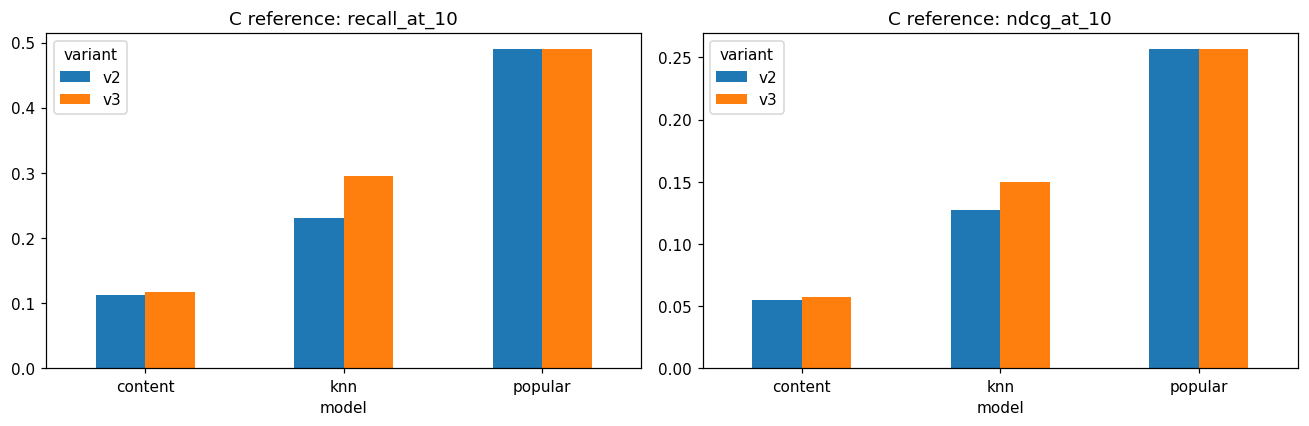

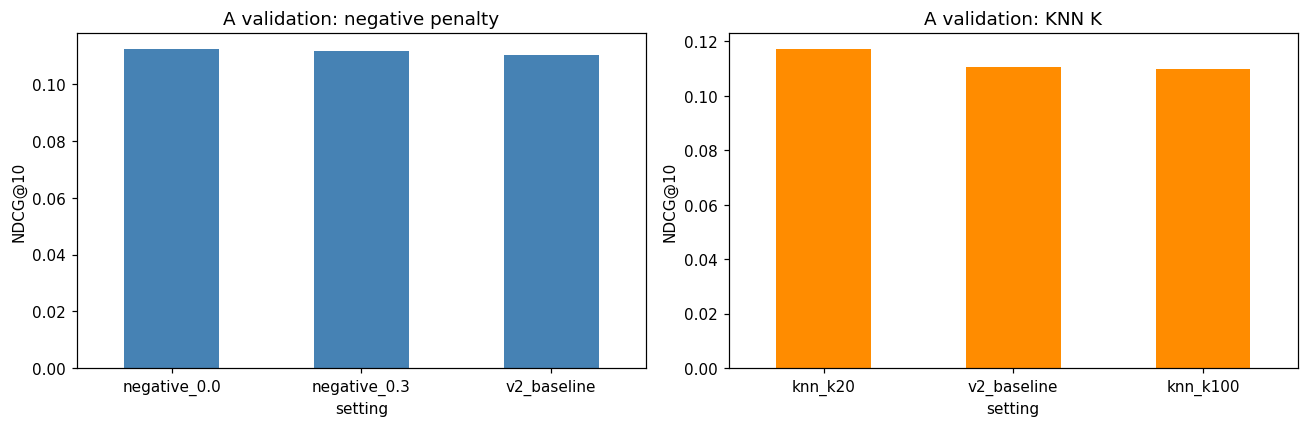

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['recall_at_10','ndcg_at_10']):
    c_metrics.pivot(index='model', columns='variant', values=metric).reindex(['content','knn','popular']).plot.bar(ax=ax, rot=0)
    ax.set_title('C reference: ' + metric)
    ax.set_xlabel('model')
    ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
v = validation[validation.model == 'knn'].set_index('variant')
v.loc[['negative_0.0','negative_0.3','v2_baseline'],'ndcg_at_10'].plot.bar(ax=axes[0], rot=0, color='steelblue')
axes[0].set(title='A validation: negative penalty', ylabel='NDCG@10', xlabel='setting')
v.loc[['knn_k20','v2_baseline','knn_k100'],'ndcg_at_10'].plot.bar(ax=axes[1], rot=0, color='darkorange')
axes[1].set(title='A validation: KNN K', ylabel='NDCG@10', xlabel='setting')
fig.tight_layout()
plt.show()

## 7. 추천 사례 확인

저장된 C 사용자 한 명의 정답과 추천을 표시합니다. 사용자 ID는 저장하지 않았습니다. `is_target=True`가 숨겨 둔 정답입니다. 이 예시는 성공 사례를 고른 것이 아니라 기록된 첫 번째 평가 예시입니다.

In [9]:
example = report['anonymous_example']['v3']
print('긍정 입력:', example['positive_inputs'])
print('부정 입력:', example['negative_inputs'])
print('숨긴 정답:', example['targets'])
for model in ['content','knn','popular']:
    print('\n', model)
    display(pd.DataFrame(example['rankings'][model]))

긍정 입력: [{'app_id': '211500', 'title': 'RaceRoom Racing Experience'}]
부정 입력: []
숨긴 정답: [{'app_id': '41070', 'title': 'Serious Sam 3: BFE'}]

 content

 knn

 popular


,rank,app_id,title,score,is_target
0,1,262690,Little Racers STREET,0.205522,False
1,2,212070,Star Conflict,0.197290,False
2,3,236390,War Thunder,0.190840,False
3,4,302710,BlazeRush,0.186302,False
4,5,570,Dota 2,0.185637,False
5,6,294160,Galcon 2: Galactic Conquest,0.173629,False
6,7,317360,Double Action: Boogaloo,0.163585,False
7,8,301520,Robocraft,0.160957,False
8,9,298260,Only If,0.159205,False
9,10,207140,SpeedRunners,0.158434,False


,rank,app_id,title,score,is_target
0,1,270750,Realms of Arkania 2 - Star Trail Classic,0.016575,False
1,2,298520,Orbital Gear,0.016273,False
2,3,270760,Realms of Arkania 3 - Shadows over Riva Classic,0.015131,False
3,4,440,Team Fortress 2,0.000000,False
4,5,570,Dota 2,0.000000,False
5,6,4000,Garry's Mod,0.000000,False
6,7,304930,Unturned,0.000000,False
7,8,218620,PAYDAY 2,0.000000,False
8,9,730,Counter-Strike: Global Offensive,0.000000,False
9,10,49520,Borderlands 2,0.000000,False


,rank,app_id,title,score,is_target
0,1,440,Team Fortress 2,25280.0,False
1,2,570,Dota 2,22390.0,False
2,3,4000,Garry's Mod,21517.0,False
3,4,304930,Unturned,17044.0,False
4,5,218620,PAYDAY 2,14843.0,False
5,6,730,Counter-Strike: Global Offensive,14438.0,False
6,7,49520,Borderlands 2,14343.0,False
7,8,200510,XCOM: Enemy Unknown,13187.0,False
8,9,1250,Killing Floor,12622.0,False
9,10,220200,Kerbal Space Program,11477.0,False


## 8. 새로 학습한 v3 모델로 직접 추천

공유 패키지에는 모델 파일이 들어 있지 않습니다. 위의 재학습 셀을 실행해 `version_results/v2_v3_모델.joblib`를 만든 뒤 아래 셀을 실행하세요. 신뢰할 수 있는 모델 파일만 여세요.

In [ ]:
model_path = RESULT_DIR/'v2_v3_모델.joblib'
if not model_path.is_file():
    print('모델 파일이 없습니다. 위에서 재학습하면 이 셀에서 새 예측을 할 수 있습니다.')
else:
    bundle = joblib.load(model_path)
    positive_ids = [x['app_id'] for x in example['positive_inputs']]
    negative_ids = [x['app_id'] for x in example['negative_inputs']]
    for model, rows in predict(bundle, 'v3', positive_ids, negative_ids).items():
        print('\n', model)
        display(pd.DataFrame(rows))

## 해석의 한계

v1과 v3의 기간과 사용자는 다릅니다. C는 이미 확인한 데이터이며 A와 실제 사용자 중복을 확인할 수 없습니다. B 메타데이터는 리뷰보다 나중에 만들어졌을 수 있고 A 내부 검증은 시간 분할이 아닙니다. 자세한 결과와 발표 자료 주의사항은 README를 참고하세요.